# 1.Import libraries

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline


# 2.Read CSV

In [43]:
data = pd.read_csv("california_cities.csv")
print("Rows and columns:", data.shape)

Rows and columns: (482, 14)


In [44]:
data.head()

,Unnamed: 0,city,latd,longd,elevation_m,elevation_ft,population_total,area_total_sq_mi,area_land_sq_mi,area_water_sq_mi,area_total_km2,area_land_km2,area_water_km2,area_water_percent
0,0,Adelanto,34.576111,-117.432778,875.0,2871.0,31765,56.027,56.009,0.018,145.107,145.062,0.046,0.03
1,1,AgouraHills,34.153333,-118.761667,281.0,922.0,20330,7.822,7.793,0.029,20.260,20.184,0.076,0.37
2,2,Alameda,37.756111,-122.274444,NaN,33.0,75467,22.960,10.611,12.349,59.465,27.482,31.983,53.79
3,3,Albany,37.886944,-122.297778,NaN,43.0,18969,5.465,1.788,3.677,14.155,4.632,9.524,67.28
4,4,Alhambra,34.081944,-118.135000,150.0,492.0,83089,7.632,7.631,0.001,19.766,19.763,0.003,0.01


We See many negative numbers on this table!!

# 3. Dataset Remains Original

In [45]:
df = data.copy()

# 4.Informaton Structure

In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 482 entries, 0 to 481
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Unnamed: 0          482 non-null    int64  
 1   city                482 non-null    object 
 2   latd                482 non-null    float64
 3   longd               482 non-null    float64
 4   elevation_m         434 non-null    float64
 5   elevation_ft        470 non-null    float64
 6   population_total    482 non-null    int64  
 7   area_total_sq_mi    480 non-null    float64
 8   area_land_sq_mi     482 non-null    float64
 9   area_water_sq_mi    481 non-null    float64
 10  area_total_km2      477 non-null    float64
 11  area_land_km2       478 non-null    float64
 12  area_water_km2      478 non-null    float64
 13  area_water_percent  477 non-null    float64
dtypes: float64(11), int64(2), object(1)
memory usage: 52.8+ KB


In [47]:
df.describe()

,Unnamed: 0,latd,longd,elevation_m,elevation_ft,population_total,area_total_sq_mi,area_land_sq_mi,area_water_sq_mi,area_total_km2,area_land_km2,area_water_km2,area_water_percent
count,482.000000,482.000000,482.000000,434.000000,470.000000,4.820000e+02,480.000000,482.000000,481.000000,477.000000,478.000000,478.000000,477.000000
mean,240.500000,36.095088,-119.837714,180.416705,567.168723,6.489493e+04,18.442183,16.840981,1.589630,46.753283,43.547021,3.125178,5.301801
std,139.285678,2.298006,2.147676,309.531825,1001.265722,2.032041e+05,36.363230,32.694647,9.490386,90.972269,84.933022,11.562269,14.656428
min,0.000000,32.578333,-124.263333,-34.000000,-180.000000,1.000000e+00,0.314000,0.314000,0.000000,0.813000,0.813000,0.000000,0.000000
25%,120.250000,33.977292,-121.954931,22.000000,69.000000,1.090200e+04,3.708250,3.506500,0.000000,9.551000,9.025000,0.000250,0.000000
50%,240.500000,36.204722,-119.708611,67.000000,200.000000,2.905750e+04,9.093000,8.362000,0.029000,23.551000,21.533000,0.078500,0.340000
75%,360.750000,37.886667,-117.977292,173.500000,515.000000,6.646650e+04,19.878250,19.090000,0.244000,51.772000,49.322000,0.623250,1.870000
max,481.000000,41.965000,-114.596389,2402.000000,7880.000000,3.884307e+06,503.000000,469.000000,185.020000,1302.000000,1214.000000,122.270000,84.580000


# 5.Requirment Analysis

In [48]:
area_water= [
    "area_water_sq_mi",
    "area_water_km2",
    "area_water_percent"
]

print("area_water dtypes:")
print(df[area_water].dtypes)


area_water dtypes:
area_water_sq_mi      float64
area_water_km2        float64
area_water_percent    float64
dtype: object


# 6.Missing Values

In [49]:
missing_values = df.isna().sum().sort_values(ascending=False)
print(missing_values)

elevation_m           48
elevation_ft          12
area_total_km2         5
area_water_percent     5
area_land_km2          4
area_water_km2         4
area_total_sq_mi       2
area_water_sq_mi       1
Unnamed: 0             0
city                   0
latd                   0
longd                  0
population_total       0
area_land_sq_mi        0
dtype: int64


In [50]:
print("missing values in water area:")
print(df[area_water].isna().sum())


missing values in water area:
area_water_sq_mi      1
area_water_km2        4
area_water_percent    5
dtype: int64


# 7. Data Preprocessing

### Filling Missing Values in Square Kilometers

One square mile is equal to `2.58999` square kilometers. First, we need to identify the rows where `area_water_km2` is missing. Then, if the corresponding `area_water_sq_mi` value is available, we can calculate the missing value in square kilometers using the conversion factor.

In [51]:
missing_water_rows = df[
    df[area_water].isna().any(axis=1)
]

display(
    missing_water_rows[
        ["city"] + area_water
    ]
)


,city,area_water_sq_mi,area_water_km2,area_water_percent
143,FortBragg,NaN,0.1,NaN
197,JurupaValley,0.200,0.6,NaN
237,LosAltos,0.000,NaN,NaN
370,SanFrancisco,185.020,NaN,80.0
393,SantaMonica,0.001,NaN,NaN
443,UnionCity,0.000,NaN,NaN


داده های ردیف 237 و 443 حاوی مقدار صفر هستنید ایا هنگام تبدیل به کیلومترمربع میتوان خروجی منطقی کسب کرد؟ یا باید خروجی صفر را به عنوان مساحت آبی صفر کیلومترمربع در نطر گرفت؟

پاکسازی دیتاست را ادامه میدهیم و با خروجی صفر مشکلی نداریم*

In [52]:
convert_MILE_TO_KM2 = 2.58999

df["area_water_km2"] = df["area_water_km2"].fillna(
    df["area_water_sq_mi"] * convert_MILE_TO_KM2
)

print("missing values after convert:")
print(df[area_water].isna().sum())


missing values after convert:
area_water_sq_mi      1
area_water_km2        0
area_water_percent    5
dtype: int64


#### *one missing value still remain on area_water_sq_mi* 
So I decided to drop this column(area_water_sq_mi)

In [62]:
df.drop(columns=["area_water_sq_mi"], inplace=True)

In [63]:
df.shape

(482, 13)

#### Analyses Negative Measures

In [66]:
Negative_Measures = df[
    (df["area_water_km2"] < 0) |
    (df["area_water_percent"] < 0)
]

print("Negative Records:")
display(Negative_Measures["city"].shape)


Negative Records:


(0,)

# 8.Top 5 cities

In [69]:
ranking_data = df[df["area_water_km2"] >= 0]

top_5_water_cities = (
    ranking_data
    .sort_values(by="area_water_km2", ascending=False)
    .head(5)
)

print(top_5_water_cities[["city", "area_water_km2"]])

             city  area_water_km2
370  SanFrancisco       479.19995
367      SanDiego       122.27000
239    LosAngeles        88.00000
285  NewportBeach        75.55700
93       Coronado        64.06200


In [70]:
top_5_water_cities = (
    df.nlargest(5, "area_water_km2")
      [["city", "area_water_km2"]]
)

print(top_5_water_cities.to_string(index=False))

        city  area_water_km2
SanFrancisco       479.19995
    SanDiego       122.27000
  LosAngeles        88.00000
NewportBeach        75.55700
    Coronado        64.06200


# 9. Bar Plot top 5 cities

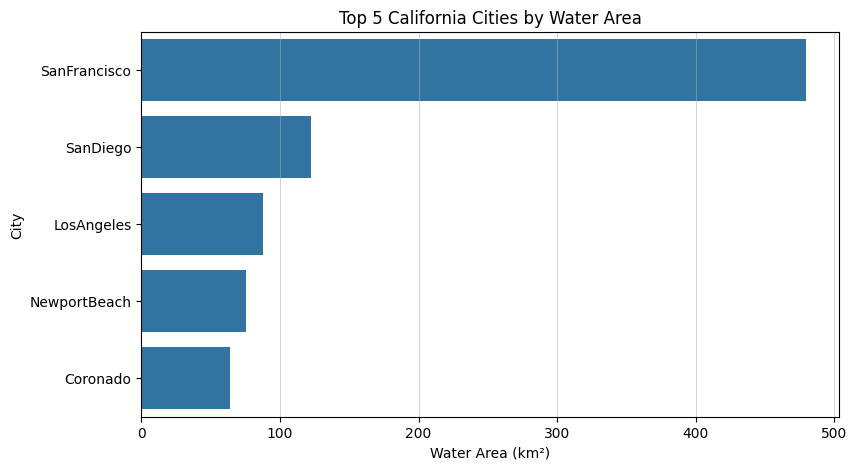

In [80]:
top_5 = top_5_water_cities.sort_values("area_water_km2")

plt.figure(figsize=(9, 5))

sns.barplot(
    data=top_5,
    x="area_water_km2",
    y="city"
)

plt.xlabel("Water Area (km²)")
plt.ylabel("City")
plt.title("Top 5 California Cities by Water Area")
plt.grid(axis="x", alpha=0.5)
plt.gca().invert_yaxis()
plt.show()

# 10.Conclusion


 The analysis identified the five California cities with the largest water areas. San Francisco ranked first, followed by San Diego, Los Angeles, Newport Beach, and Coronado. A horizontal bar chart was used to compare their water areas clearly and visually.